# Discharge Outcome Prediction Model

Predicts a patient's discharge outcome - Complete Recovery, Partial Recovery, or Further
Interventions - using information available by the end of treatment. Unlike the severity model,
this one runs **after** treatment is finished, so length-of-stay, transfers, investigations, and
management given are all legitimate inputs here, not leakage.

**Excluded on principle, same reasoning as the severity work:**
- Financial/social fields (income, occupation, education, family status, expenditure) - these
  measure circumstance, not clinical outcome, and risk teaching the model that poorer patients
  recover worse for reasons that have nothing to do with their actual injury.
- Hospital identity (`Current Hospital Name`, `First Hospital Name`) - risks learning "which
  hospital" as a predictor instead of genuine clinical signal.
- `severity_label` / `composite` - built partly from `Discharge Outcome` itself. Using either as a
  feature here would mean predicting the target from a derivative of the target. Loaded from the
  pre-severity dataset (`Preprocessed Dataset.csv`) specifically to make this mistake structurally
  impossible, not just something to remember to avoid.

**Same discipline as the severity notebook throughout:** test data split off first and untouched
until the final evaluation, every feature check and decision made on training data only, real
missing values kept as missing (no `-999`, no blanket fill).

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from scipy import stats

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (recall_score, precision_score, f1_score, fbeta_score,
                              classification_report, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.base import clone

from catboost import CatBoostClassifier, Pool
import xgboost as xgb
import lightgbm as lgb
import shap
import matplotlib.pyplot as plt
import joblib, json, os

RANDOM_STATE = 42
os.makedirs("artifacts", exist_ok=True)

## 1. Load the data and set the candidate feature list

Loaded from `Preprocessed Dataset.csv` - the cleaned dataset from before the severity label was
built, so there is no `severity_label`/`composite` column to accidentally include.

A broad candidate list to start, spanning demographics, accident circumstances, injury detail,
length of stay, escalation of care, and treatment given - narrowed down by the statistical check
in Section 3, the same process used for the severity model's 8-to-5 narrowing.

In [2]:
TARGET = 'Discharge Outcome'

CANDIDATE_FEATURES = [
    # demographics
    'Age', 'Gender',
    # accident circumstances
    'Mode of Transport to the Hospital', 'Time Taken To Reach Hospital', 'Vehicle Type',
    'Helmet Worn', 'Collision With ', 'Approximate Speed', 'Road Type', 'Road Condition',
    'Visiblity', 'Road Signals Exist', 'Collision Force From', 'Alcohol Consumption', 'Illicit Drugs',
    # injury detail
    'Site of Injury No1', 'Type of injury No 1', 'Site of injury No 2', 'Type of Injury No 2',
    # length of stay
    'Number of days in first ward', 'Number of days in Second ward', 'Number of days in Third ward',
    'Number of Wards Stayed',
    # escalation of care
    'Transfer To Next Hospital', 'Treatment During Tranfer', 'State of Transfer',
    # treatment given
    'Investigation Done', 'Management Name 1', 'Management Name 2',
]

df = pd.read_csv('Preprocessed Dataset.csv')
df = df.rename(columns={'Collision With ': 'Collision With'})
CANDIDATE_FEATURES = [c if c != 'Collision With ' else 'Collision With' for c in CANDIDATE_FEATURES]

# the single 'others' row has no usable ground truth - drop it, same as the severity notebook did
df = df[df[TARGET] != 'others'].copy()

print(df.shape)
df[TARGET].value_counts()

(6177, 132)


Discharge Outcome
partial recovery         5314
complete recovery         545
further interventions     318
Name: count, dtype: int64

## 2. Combine the three ward-day columns into one length-of-stay number

Same construction used in the severity label notebook: three separate ward-day columns, mostly
empty because most patients never reach a second or third ward, combined into one `total_days`
number. `min_count=1` means a patient with all three genuinely unrecorded stays `NaN`, not a
silent 0.

In [3]:
ward_cols = ['Number of days in first ward', 'Number of days in Second ward', 'Number of days in Third ward']
for c in ward_cols:
    df[c] = pd.to_numeric(df[c], errors='coerce')
    early_mask = df[c + '_missing_reason'] == 'early_discharge'
    df.loc[early_mask, c] = df.loc[early_mask, c].fillna(0)

df['total_days'] = df[ward_cols].sum(axis=1, skipna=True, min_count=1)
df['Number of Wards Stayed'] = pd.to_numeric(df['Number of Wards Stayed'], errors='coerce')

CANDIDATE_FEATURES = [c for c in CANDIDATE_FEATURES if c not in ward_cols] + ['total_days']
print("Missing total_days:", df['total_days'].isna().mean())

Missing total_days: 0.0


## 3. Split into training and test data, first

80/20 split, stratified on `Discharge Outcome`, before any feature is checked or any decision is
made. The test set is not opened again until Section 10.

In [4]:
X = df[CANDIDATE_FEATURES].copy()
y = df[TARGET].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("\nTrain class balance:\n", y_train.value_counts(normalize=True))
print("\nTest class balance:\n", y_test.value_counts(normalize=True))

Train: (4941, 27)  Test: (1236, 27)

Train class balance:
 Discharge Outcome
partial recovery         0.860352
complete recovery        0.088241
further interventions    0.051407
Name: proportion, dtype: float64

Test class balance:
 Discharge Outcome
partial recovery         0.860032
complete recovery        0.088188
further interventions    0.051780
Name: proportion, dtype: float64


## 4. Check the candidate features actually matter - training data only

`Age`, `Time Taken To Reach Hospital`, `total_days`, and `Number of Wards Stayed` are ordered or
truly numeric - checked with a test that looks at whether the ordering itself relates to the
outcome. Everything else is a plain category, checked with a test for whether the outcome mix
genuinely differs by category, plus a strength score from 0 to 1 (how strong the relationship
really is), so a technically-real but tiny relationship doesn't get treated the same as a strong
one.

In [5]:
AGE_ORDER = ['1-9','10-19','20-29','30-39','40-49','50-59','60-69','70-79','80-89','90-100']
TIME_ORDER = ['less than 15 minutes','15 minutes - 30 minutes','30 minutes - 1 hour',
              '1 hour - 2 hour','more than 2 hour']

NUMERIC_LIKE = ['total_days', 'Number of Wards Stayed']
ORDINAL_FEATURES = ['Age', 'Time Taken To Reach Hospital']
NOMINAL_FEATURES = [c for c in CANDIDATE_FEATURES if c not in ORDINAL_FEATURES + NUMERIC_LIKE]

val_df = X_train.copy()
val_df[TARGET] = y_train.values

print("--- Age / Time-to-hospital: does the ORDER relate to outcome? ---")
ordinal_results = {}
for col, order in [('Age', AGE_ORDER), ('Time Taken To Reach Hospital', TIME_ORDER)]:
    mapping = {v: i for i, v in enumerate(order)}
    groups = [g[col].map(mapping).dropna() for _, g in val_df.groupby(TARGET)]
    h, p = stats.kruskal(*groups)
    ordinal_results[col] = {'H': h, 'p': p}
    print(f"{col:35s} H={h:7.2f}  p={p:.4g}")

print("\n--- total_days / wards stayed: does the value relate to outcome? ---")
numeric_results = {}
for col in NUMERIC_LIKE:
    groups = [g[col].dropna() for _, g in val_df.groupby(TARGET)]
    h, p = stats.kruskal(*groups)
    numeric_results[col] = {'H': h, 'p': p}
    print(f"{col:35s} H={h:7.2f}  p={p:.4g}")

--- Age / Time-to-hospital: does the ORDER relate to outcome? ---
Age                                 H=  19.77  p=5.088e-05
Time Taken To Reach Hospital        H=   3.74  p=0.154

--- total_days / wards stayed: does the value relate to outcome? ---
total_days                          H=  54.45  p=1.502e-12
Number of Wards Stayed              H=   3.18  p=0.2036


In [6]:
print("--- Other categories: does the outcome mix actually differ by category? ---")
cat_results = {}
for col in NOMINAL_FEATURES:
    ct = pd.crosstab(val_df[col], val_df[TARGET])
    chi2, p, dof, exp = stats.chi2_contingency(ct)
    n = ct.values.sum()
    cramers_v = np.sqrt(chi2 / (n * (min(ct.shape) - 1)))
    cat_results[col] = {'chi2': chi2, 'p': p, 'cramers_v': cramers_v}
    flag = "  <-- WEAK/NO SIGNAL -> DROP" if p > 0.05 or cramers_v < 0.05 else ""
    print(f"{col:35s} chi2={chi2:8.2f}  p={p:.4g}  Cramer'sV={cramers_v:.3f}{flag}")

--- Other categories: does the outcome mix actually differ by category? ---
Gender                              chi2=   39.41  p=2.769e-09  Cramer'sV=0.089
Mode of Transport to the Hospital   chi2=  124.91  p=1.513e-24  Cramer'sV=0.148
Vehicle Type                        chi2=    3.07  p=0.2158  Cramer'sV=0.029  <-- WEAK/NO SIGNAL -> DROP
Helmet Worn                         chi2=    3.59  p=0.1665  Cramer'sV=0.035  <-- WEAK/NO SIGNAL -> DROP
Collision With                      chi2=   84.83  p=1.015e-08  Cramer'sV=0.107
Approximate Speed                   chi2=   95.53  p=2.146e-18  Cramer'sV=0.115
Road Type                           chi2=  234.60  p=1.348e-49  Cramer'sV=0.174
Road Condition                      chi2=    7.36  p=0.02521  Cramer'sV=0.043  <-- WEAK/NO SIGNAL -> DROP
Visiblity                           chi2=   15.25  p=0.000489  Cramer'sV=0.062
Road Signals Exist                  chi2=    3.80  p=0.1493  Cramer'sV=0.034  <-- WEAK/NO SIGNAL -> DROP
Collision Force From    

In [7]:
# decision, made from the numbers above - both the categorical checks AND the
# ordinal/numeric checks feed into this, not just the categorical ones
DROP_THRESHOLD_V = 0.05
DROP_THRESHOLD_P = 0.05

features_to_drop = [c for c, r in cat_results.items() if r['p'] > DROP_THRESHOLD_P or r['cramers_v'] < DROP_THRESHOLD_V]
features_to_drop += [c for c, r in ordinal_results.items() if r['p'] > DROP_THRESHOLD_P]
features_to_drop += [c for c, r in numeric_results.items() if r['p'] > DROP_THRESHOLD_P]

print("Dropping (no real relationship to outcome, checked on training data only):", features_to_drop)

FEATURES = [f for f in CANDIDATE_FEATURES if f not in features_to_drop]
CAT_FEATURES = [f for f in NOMINAL_FEATURES if f not in features_to_drop]
print(f"\nFinal feature set ({len(FEATURES)}):", FEATURES)

X_train = X_train[FEATURES].copy()
X_test = X_test[FEATURES].copy()

Dropping (no real relationship to outcome, checked on training data only): ['Vehicle Type', 'Helmet Worn', 'Road Condition', 'Road Signals Exist', 'Illicit Drugs', 'Treatment During Tranfer', 'Time Taken To Reach Hospital', 'Number of Wards Stayed']

Final feature set (19): ['Age', 'Gender', 'Mode of Transport to the Hospital', 'Collision With', 'Approximate Speed', 'Road Type', 'Visiblity', 'Collision Force From', 'Alcohol Consumption', 'Site of Injury No1', 'Type of injury No 1', 'Site of injury No 2', 'Type of Injury No 2', 'Transfer To Next Hospital', 'State of Transfer', 'Investigation Done', 'Management Name 1', 'Management Name 2', 'total_days']


## 5. Clean up rare categories, then handle missing values

Same approach as the severity model: any category with fewer than 20 training rows gets grouped
into "Other" before modeling starts - a category with 1-3 examples isn't something a model can
learn a real pattern from, and it breaks cross-validation if a fold's training split happens to
have zero examples of it.

**Missing values, real gaps stay real, with one necessary exception:** CatBoost needs its
categorical inputs as text, so missing categories are written as the literal word `"missing"` -
not a guess at an answer, just giving "we don't know" its own label. The other 4 models
(Logistic Regression, Random Forest, XGBoost, LightGBM) can't handle blanks at all, so they get a
filler value (median for numbers, most-common for categories) inside a pipeline fit on training
data only.

In [8]:
RARE_CATEGORY_MIN_COUNT = 20
rare_category_maps = {}
for col in CAT_FEATURES:
    train_counts = X_train[col].value_counts(dropna=True)
    keep = set(train_counts[train_counts >= RARE_CATEGORY_MIN_COUNT].index)
    if len(keep) < train_counts.shape[0]:
        rare_category_maps[col] = keep
        n_dropped = train_counts[train_counts < RARE_CATEGORY_MIN_COUNT].shape[0]
        print(f"{col}: {n_dropped} rare categories (< {RARE_CATEGORY_MIN_COUNT} train rows) -> merged into 'Other'")

def consolidate_rare(series, keep_set):
    return series.where(series.isna() | series.isin(keep_set), 'Other')

for col, keep_set in rare_category_maps.items():
    X_train[col] = consolidate_rare(X_train[col], keep_set)
    X_test[col] = consolidate_rare(X_test[col], keep_set)   # same train-derived mapping, no test leakage

Collision With: 2 rare categories (< 20 train rows) -> merged into 'Other'
Approximate Speed: 1 rare categories (< 20 train rows) -> merged into 'Other'
Site of Injury No1: 10 rare categories (< 20 train rows) -> merged into 'Other'
Type of injury No 1: 6 rare categories (< 20 train rows) -> merged into 'Other'
Site of injury No 2: 27 rare categories (< 20 train rows) -> merged into 'Other'
Type of Injury No 2: 6 rare categories (< 20 train rows) -> merged into 'Other'
State of Transfer: 5 rare categories (< 20 train rows) -> merged into 'Other'
Investigation Done: 3 rare categories (< 20 train rows) -> merged into 'Other'
Management Name 1: 5 rare categories (< 20 train rows) -> merged into 'Other'
Management Name 2: 7 rare categories (< 20 train rows) -> merged into 'Other'


In [9]:
X_train_enc = X_train.copy()
X_test_enc = X_test.copy()

# only encode ordinal columns that actually survived Section 4's validation - Time Taken To
# Reach Hospital didn't (p=0.154), so it won't be in FEATURES if that happens
for col, order in [('Age', AGE_ORDER), ('Time Taken To Reach Hospital', TIME_ORDER)]:
    if col not in X_train_enc.columns:
        continue
    mapping = {v: i for i, v in enumerate(order)}
    X_train_enc[col] = X_train_enc[col].map(mapping)
    X_test_enc[col] = X_test_enc[col].map(mapping)

for c in CAT_FEATURES:
    X_train_enc[c] = X_train_enc[c].astype(object).where(X_train_enc[c].notna(), 'missing').astype(str)
    X_test_enc[c] = X_test_enc[c].astype(object).where(X_test_enc[c].notna(), 'missing').astype(str)

cat_idx = [X_train_enc.columns.get_loc(c) for c in CAT_FEATURES]

NUM_FEATURES_FOR_SKLEARN = [c for c in FEATURES if c in ORDINAL_FEATURES + NUMERIC_LIKE]
sk_preprocess = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), NUM_FEATURES_FOR_SKLEARN),
    ('cat', Pipeline([
        ('impute', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ]), CAT_FEATURES)
])

skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
print("Setup complete. Final features:", FEATURES)

Setup complete. Final features: ['Age', 'Gender', 'Mode of Transport to the Hospital', 'Collision With', 'Approximate Speed', 'Road Type', 'Visiblity', 'Collision Force From', 'Alcohol Consumption', 'Site of Injury No1', 'Type of injury No 1', 'Site of injury No 2', 'Type of Injury No 2', 'Transfer To Next Hospital', 'State of Transfer', 'Investigation Done', 'Management Name 1', 'Management Name 2', 'total_days']


## 6. Baseline model

CatBoost, default-ish settings, class-balanced. The 3 classes are badly imbalanced (roughly
86% Partial Recovery, 9% Complete Recovery, 5% Further Interventions) - without balancing, a model
can score well by mostly ignoring the rare classes entirely, which for this tool means missing the
patients who need the most follow-up. This is a reference number, not the final answer.

The number that matters most throughout this notebook: **recall on Further Interventions** -
missing a patient who actually needed more care is the worst failure this model could make.

In [10]:
def per_class_recall(y_true, y_pred, target_class='further interventions'):
    labels = sorted(y_true.unique())
    recalls = recall_score(y_true, y_pred, labels=labels, average=None)
    return dict(zip(labels, recalls))[target_class]

baseline_recalls = []
for tr_idx, val_idx in skf.split(X_train_enc, y_train):
    Xt, Xv = X_train_enc.iloc[tr_idx], X_train_enc.iloc[val_idx]
    yt, yv = y_train.iloc[tr_idx], y_train.iloc[val_idx]
    m = CatBoostClassifier(random_state=RANDOM_STATE, verbose=0, iterations=300,
                            auto_class_weights='Balanced', loss_function='MultiClass')
    m.fit(Xt, yt, cat_features=cat_idx, verbose=0)
    pred = m.predict(Xv).flatten()
    baseline_recalls.append(per_class_recall(yv, pred))

print(f"Baseline CatBoost - 3-fold CV recall(Further Interventions): "
      f"{np.mean(baseline_recalls):.3f} +/- {np.std(baseline_recalls):.3f}")

Baseline CatBoost - 3-fold CV recall(Further Interventions): 0.551 +/- 0.016


## 7. Compare several different models

Same 5 candidates as the severity model, scored the same way: recall on the class that matters
most (Further Interventions), with macro-averaged precision/F1 tracked alongside so a model can't
"win" by just calling everything Further Interventions.

In [11]:
def cv_evaluate(build_fn, catboost=False, xgboost_encode=False):
    rec, prec, f1 = [], [], []
    for tr_idx, val_idx in skf.split(X_train_enc, y_train):
        Xt, Xv = X_train_enc.iloc[tr_idx], X_train_enc.iloc[val_idx]
        yt, yv = y_train.iloc[tr_idx], y_train.iloc[val_idx]
        m = build_fn()
        if catboost:
            m.fit(Xt, yt, cat_features=cat_idx, verbose=0)
            pred = m.predict(Xv).flatten()
        elif xgboost_encode:
            classes = sorted(yt.unique())
            label_map = {c: i for i, c in enumerate(classes)}
            inv_map = {i: c for c, i in label_map.items()}
            m.fit(Xt, yt.map(label_map))
            pred = pd.Series(m.predict(Xv)).map(inv_map).values
        else:
            m.fit(Xt, yt)
            pred = m.predict(Xv)
        rec.append(per_class_recall(yv, pred))
        prec.append(precision_score(yv, pred, average='macro'))
        f1.append(f1_score(yv, pred, average='macro'))
    return {'recall_further_interventions': np.mean(rec), 'recall_std': np.std(rec),
            'precision_macro': np.mean(prec), 'f1_macro': np.mean(f1)}

comparison = {}

comparison['CatBoost'] = cv_evaluate(
    lambda: CatBoostClassifier(random_state=RANDOM_STATE, verbose=0, iterations=300,
                                auto_class_weights='Balanced', loss_function='MultiClass'),
    catboost=True
)

comparison['LogisticRegression'] = cv_evaluate(
    lambda: Pipeline([('pre', sk_preprocess),
                       ('clf', LogisticRegression(max_iter=1000, class_weight='balanced'))])
)

comparison['RandomForest'] = cv_evaluate(
    lambda: Pipeline([('pre', sk_preprocess),
                       ('clf', RandomForestClassifier(n_estimators=80, random_state=RANDOM_STATE,
                                                       class_weight='balanced'))])
)

comparison['XGBoost'] = cv_evaluate(
    lambda: Pipeline([('pre', sk_preprocess),
                       ('clf', xgb.XGBClassifier(n_estimators=80, random_state=RANDOM_STATE,
                                                  eval_metric='mlogloss', objective='multi:softprob'))]),
    xgboost_encode=True
)

comparison['LightGBM'] = cv_evaluate(
    lambda: Pipeline([('pre', sk_preprocess),
                       ('clf', lgb.LGBMClassifier(n_estimators=80, random_state=RANDOM_STATE,
                                                   class_weight='balanced', verbosity=-1))])
)

results_df = pd.DataFrame(comparison).T.sort_values('recall_further_interventions', ascending=False)
results_df

,recall_further_interventions,recall_std,precision_macro,f1_macro
LogisticRegression,0.661391,0.024468,0.505164,0.539048
LightGBM,0.563165,0.042397,0.578340,0.613178
CatBoost,0.551214,0.015561,0.577788,0.610018
XGBoost,0.338562,0.019564,0.637243,0.567341
RandomForest,0.082773,0.017232,0.702945,0.405831


**Read this table before moving on.** Whichever model scores highest on recall(Further
Interventions) moves to tuning, plus CatBoost every time regardless of rank - same reasoning as
the severity model: it handles missing values and categories on its own, which makes it the safer
real-world choice if its score isn't far behind the leader.

In [12]:
top_models = [results_df.index[0]]
if 'CatBoost' not in top_models:
    top_models.append('CatBoost')
print("Tuning:", top_models)

Tuning: ['LogisticRegression', 'CatBoost']


## 8. Fine-tune the best model(s)

A wide random search over settings for each model chosen above, still scored on
recall(Further Interventions), still using only the training data.

In [13]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import make_scorer

fi_scorer = make_scorer(lambda yt, yp: per_class_recall(pd.Series(yt).reset_index(drop=True),
                                                          pd.Series(yp).reset_index(drop=True)))

tuned_models = {}

if 'LogisticRegression' in top_models:
    pipe = Pipeline([('pre', sk_preprocess),
                      ('clf', LogisticRegression(max_iter=2000, class_weight='balanced'))])
    param_dist = {
        'clf__C': [0.01, 0.03, 0.1, 0.3, 1, 3, 10],
        'clf__penalty': ['l2'],
        'clf__solver': ['lbfgs', 'liblinear']
    }
    search = RandomizedSearchCV(pipe, param_dist, n_iter=10, scoring=fi_scorer,
                                 cv=skf, random_state=RANDOM_STATE, n_jobs=-1)
    search.fit(X_train_enc, y_train)
    tuned_models['LogisticRegression'] = search.best_estimator_
    print("LogisticRegression best:", search.best_params_, "recall=%.3f" % search.best_score_)

if 'CatBoost' in top_models:
    rng = np.random.RandomState(RANDOM_STATE)
    param_space = {
        'depth': [5, 6],
        'learning_rate': [0.08],
        'l2_leaf_reg': [5],
        'iterations': [150],
        'border_count': [64],
    }
    N_ITER = 2
    sampled = set()
    while len(sampled) < N_ITER:
        combo = tuple(rng.choice(param_space[k]) for k in param_space)
        sampled.add(combo)

    best_score = -1
    best_params = None
    tuning_log = []
    for combo in sampled:
        params = dict(zip(param_space.keys(), [v.item() if hasattr(v, 'item') else v for v in combo]))
        recs = []
        for tr_idx, val_idx in skf.split(X_train_enc, y_train):
            Xt, Xv = X_train_enc.iloc[tr_idx], X_train_enc.iloc[val_idx]
            yt, yv = y_train.iloc[tr_idx], y_train.iloc[val_idx]
            m = CatBoostClassifier(random_state=RANDOM_STATE, verbose=0,
                                    auto_class_weights='Balanced', loss_function='MultiClass', **params)
            m.fit(Xt, yt, cat_features=cat_idx, verbose=0)
            recs.append(per_class_recall(yv, m.predict(Xv).flatten()))
        score = np.mean(recs)
        tuning_log.append({**params, 'recall_fi': score})
        if score > best_score:
            best_score = score
            best_params = params

    print("CatBoost search: %d random combinations tried (of %d possible)" %
          (N_ITER, np.prod([len(v) for v in param_space.values()])))
    print("CatBoost best:", best_params, "recall=%.3f" % best_score)
    print(f"\nAll {N_ITER} combinations tried, for reference:")
    print(pd.DataFrame(tuning_log).sort_values('recall_fi', ascending=False).to_string(index=False))

    final_cb = CatBoostClassifier(random_state=RANDOM_STATE, verbose=0,
                                   auto_class_weights='Balanced', loss_function='MultiClass', **best_params)
    final_cb.fit(X_train_enc, y_train, cat_features=cat_idx, verbose=0)
    tuned_models['CatBoost'] = final_cb

LogisticRegression best: {'clf__solver': 'lbfgs', 'clf__penalty': 'l2', 'clf__C': 0.03} recall=0.748
CatBoost search: 2 random combinations tried (of 2 possible)
CatBoost best: {'depth': 6, 'learning_rate': 0.08, 'l2_leaf_reg': 5, 'iterations': 150, 'border_count': 64} recall=0.689

All 2 combinations tried, for reference:
 depth  learning_rate  l2_leaf_reg  iterations  border_count  recall_fi
     6           0.08            5         150            64   0.688936
     5           0.08            5         150            64   0.677171


## 9. Choose the final model AND its class-weight balance together

A binary model can be tuned by sliding a single probability cutoff. With 3 classes, there's no
single cutoff - instead, the balance between classes is tuned by adjusting how heavily
"Further Interventions" is weighted relative to the other two during training. Push that weight up
and the model catches more Further Interventions cases, at some cost to how well it tells apart
Complete Recovery and Partial Recovery.

**The same guardrail used for the severity model, adapted for 3 classes:** try a range of extra
weight multipliers on Further Interventions, and only accept a multiplier if the other two classes
still each keep at least 40% recall - a floor against the same kind of degenerate,
call-everything-Further-Interventions result that an earlier, less careful attempt at the severity
model produced.

In [14]:
OTHER_CLASS_RECALL_FLOOR = 0.40
fi_weight_multipliers = [1, 5]

def class_weights_for_multiplier(y, multiplier, boost_class='further interventions'):
    classes = sorted(y.unique())
    base = compute_class_weight('balanced', classes=np.array(classes), y=y)
    weights = dict(zip(classes, base))
    weights[boost_class] = weights[boost_class] * multiplier
    return weights

sweep_rows = []
for name in tuned_models:
    for mult in fi_weight_multipliers:
        recs_fi, recs_cr, recs_pr = [], [], []
        for tr_idx, val_idx in skf.split(X_train_enc, y_train):
            Xt, Xv = X_train_enc.iloc[tr_idx], X_train_enc.iloc[val_idx]
            yt, yv = y_train.iloc[tr_idx], y_train.iloc[val_idx]
            weights = class_weights_for_multiplier(yt, mult)
            if name == 'CatBoost':
                classes_sorted = sorted(yt.unique())
                m = CatBoostClassifier(random_state=RANDOM_STATE, verbose=0, loss_function='MultiClass',
                                        class_weights=[weights[c] for c in classes_sorted], **best_params)
                m.fit(Xt, yt, cat_features=cat_idx, verbose=0)
                pred = m.predict(Xv).flatten()
            else:
                m = clone(tuned_models[name])
                sample_weight = yt.map(weights).values
                m.fit(Xt, yt, clf__sample_weight=sample_weight)
                pred = m.predict(Xv)
            per_class = dict(zip(sorted(yv.unique()), recall_score(yv, pred, labels=sorted(yv.unique()), average=None)))
            recs_fi.append(per_class.get('further interventions', 0))
            recs_cr.append(per_class.get('complete recovery', 0))
            recs_pr.append(per_class.get('partial recovery', 0))
        sweep_rows.append({'model': name, 'fi_multiplier': mult,
                            'recall_further_interventions': np.mean(recs_fi),
                            'recall_complete_recovery': np.mean(recs_cr),
                            'recall_partial_recovery': np.mean(recs_pr)})

sweep_df = pd.DataFrame(sweep_rows)
sweep_df

,model,fi_multiplier,recall_further_interventions,recall_complete_recovery,recall_partial_recovery
0,LogisticRegression,1,0.747993,0.669800,0.729946
1,LogisticRegression,5,0.728245,0.660589,0.741002
2,CatBoost,1,0.645752,0.699465,0.770172
3,CatBoost,5,0.870075,0.383042,0.709715


In [15]:
valid = sweep_df[(sweep_df['recall_complete_recovery'] >= OTHER_CLASS_RECALL_FLOOR) &
                  (sweep_df['recall_partial_recovery'] >= OTHER_CLASS_RECALL_FLOOR)]

if valid.empty:
    print(f"WARNING: nothing kept both other classes' recall at or above {OTHER_CLASS_RECALL_FLOOR}.")
    print("Falling back to the combination with the best Further Interventions recall available.")
    winner = sweep_df.loc[sweep_df['recall_further_interventions'].idxmax()]
else:
    winner = valid.loc[valid['recall_further_interventions'].idxmax()]

FINAL_MODEL_NAME = winner['model']
FI_MULTIPLIER = winner['fi_multiplier']
print(f"Selected: {FINAL_MODEL_NAME}, Further Interventions weight x{FI_MULTIPLIER}")
print(f"  recall(FI)={winner['recall_further_interventions']:.3f}  "
      f"recall(Complete Recovery)={winner['recall_complete_recovery']:.3f}  "
      f"recall(Partial Recovery)={winner['recall_partial_recovery']:.3f}")

final_weights = class_weights_for_multiplier(y_train, FI_MULTIPLIER)
if FINAL_MODEL_NAME == 'CatBoost':
    classes_sorted = sorted(y_train.unique())
    final_model = CatBoostClassifier(random_state=RANDOM_STATE, verbose=0, loss_function='MultiClass',
                                      class_weights=[final_weights[c] for c in classes_sorted], **best_params)
    final_model.fit(X_train_enc, y_train, cat_features=cat_idx, verbose=0)
else:
    final_model = clone(tuned_models[FINAL_MODEL_NAME])
    sample_weight = y_train.map(final_weights).values
    final_model.fit(X_train_enc, y_train, clf__sample_weight=sample_weight)

Selected: LogisticRegression, Further Interventions weight x1
  recall(FI)=0.748  recall(Complete Recovery)=0.670  recall(Partial Recovery)=0.730


## 10. Check what the model is actually paying attention to

With 3 possible outcomes instead of 2, each feature gets one importance value per outcome rather
than just one - averaged here into a single ranking, so it's easy to see which fields the model
leans on most overall. Confirms the model is relying on sensible clinical signal, not something
that shouldn't matter this much.

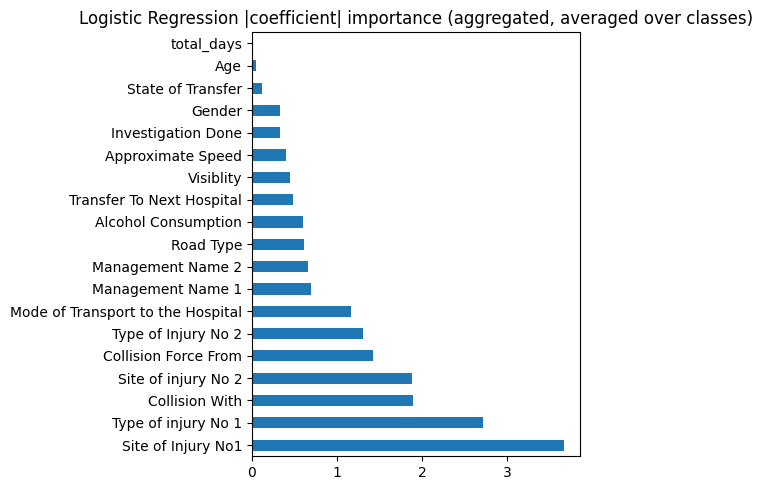

Site of Injury No1                   3.668347
Type of injury No 1                  2.714244
Collision With                       1.888784
Site of injury No 2                  1.881636
Collision Force From                 1.422718
Type of Injury No 2                  1.300433
Mode of Transport to the Hospital    1.165740
Management Name 1                    0.695489
Management Name 2                    0.657177
Road Type                            0.608362
Alcohol Consumption                  0.601746
Transfer To Next Hospital            0.484807
Visiblity                            0.446473
Approximate Speed                    0.395560
Investigation Done                   0.331745
Gender                               0.328297
State of Transfer                    0.113463
Age                                  0.043926
total_days                           0.015943
dtype: float64


In [16]:
if FINAL_MODEL_NAME == 'CatBoost':
    explainer = shap.TreeExplainer(final_model)
    X_shap = X_train_enc.copy()
    shap_values = explainer.shap_values(Pool(X_shap, cat_features=cat_idx))
    # multiclass: shap_values is (n_samples, n_features, n_classes) in recent shap versions
    if isinstance(shap_values, list):
        importance_per_class = np.mean([np.abs(sv).mean(axis=0) for sv in shap_values], axis=0)
    else:
        importance_per_class = np.abs(shap_values).mean(axis=(0, 2)) if shap_values.ndim == 3 else np.abs(shap_values).mean(axis=0)
    importance = pd.Series(importance_per_class, index=X_shap.columns).sort_values(ascending=False)
    importance.plot(kind='barh', figsize=(6, 5))
    plt.title('Average |SHAP value| across all 3 classes')
    plt.tight_layout()
    plt.savefig('artifacts/shap_summary.png', dpi=150)
    plt.show()
else:
    pre = final_model.named_steps['pre']
    clf = final_model.named_steps['clf']
    feature_names = pre.get_feature_names_out()
    coefs = pd.Series(np.abs(clf.coef_).mean(axis=0), index=feature_names)
    orig_feature_of = {}
    for fn in feature_names:
        if fn.startswith('num__'):
            orig_feature_of[fn] = fn.replace('num__', '')
        elif fn.startswith('cat__'):
            base = fn.replace('cat__', '')
            for c in CAT_FEATURES:
                if base.startswith(c + '_'):
                    orig_feature_of[fn] = c
                    break
    importance = coefs.groupby(orig_feature_of).sum().sort_values(ascending=False)
    importance.plot(kind='barh', figsize=(6, 5))
    plt.title('Logistic Regression |coefficient| importance (aggregated, averaged over classes)')
    plt.tight_layout()
    plt.savefig('artifacts/feature_importance.png', dpi=150)
    plt.show()

print(importance)

## 11. Final check on the held-out test data

Used exactly once, here, on the model and class-weight balance chosen in Section 9. Nothing above
used this data for any decision.

                       precision    recall  f1-score   support

    complete recovery       0.27      0.69      0.39       109
further interventions       0.26      0.69      0.38        64
     partial recovery       0.98      0.73      0.83      1063

             accuracy                           0.72      1236
            macro avg       0.50      0.70      0.53      1236
         weighted avg       0.88      0.72      0.77      1236



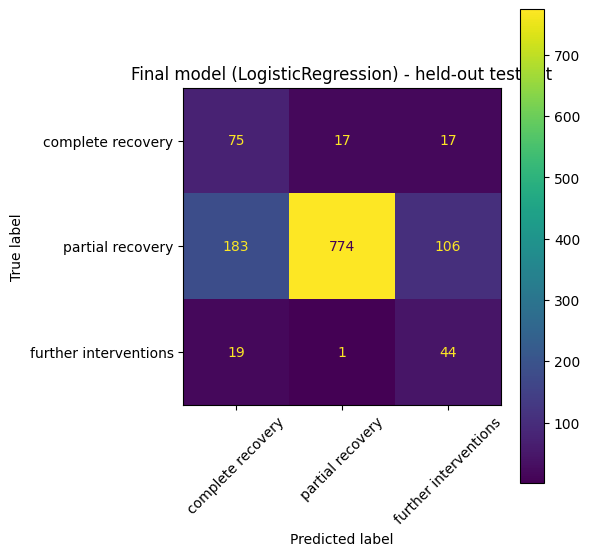


Held-out test recall per class: {'complete recovery': np.float64(0.6880733944954128), 'further interventions': np.float64(0.6875), 'partial recovery': np.float64(0.7281279397930386)}

Compare recall(Further Interventions) to the CV estimate from Section 9 - if it's
dramatically lower, that's evidence of overfitting to the training folds, not a reason
to go back and re-tune against this test set.


In [17]:
y_pred_test = final_model.predict(X_test_enc)
if hasattr(y_pred_test, 'flatten'):
    y_pred_test = y_pred_test.flatten()

print(classification_report(y_test, y_pred_test))

labels_order = ['complete recovery', 'partial recovery', 'further interventions']
cm = confusion_matrix(y_test, y_pred_test, labels=labels_order)
disp = ConfusionMatrixDisplay(cm, display_labels=labels_order)
fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(ax=ax, xticks_rotation=45)
plt.title(f'Final model ({FINAL_MODEL_NAME}) - held-out test set')
plt.tight_layout()
plt.savefig('artifacts/confusion_matrix_test.png', dpi=150)
plt.show()

test_per_class = dict(zip(sorted(y_test.unique()), recall_score(y_test, y_pred_test, labels=sorted(y_test.unique()), average=None)))
print("\nHeld-out test recall per class:", test_per_class)
print("\nCompare recall(Further Interventions) to the CV estimate from Section 9 - if it's")
print("dramatically lower, that's evidence of overfitting to the training folds, not a reason")
print("to go back and re-tune against this test set.")

## 12. A "how sure is this, really" layer

Wraps the finished model for real use. Since this model runs post-treatment, most of its 
features should genuinely be filled in by the time it's used - but the same rule still applies
for any record with real gaps, matching the severity model:
- If less than 40% of the features are filled in, refuse to predict.
- Otherwise, predict normally, but flag the result as low-confidence if the model's own probability
  for its top answer is below 60%.

In [18]:
COMPLETENESS_FLOOR = 0.40
LOW_CONF_PROB = 0.60

def predict_with_confidence(record: dict, model=final_model):
    non_missing = sum(1 for f in FEATURES if record.get(f) not in (None, np.nan) and
                       not (isinstance(record.get(f), float) and np.isnan(record.get(f))))
    completeness = non_missing / len(FEATURES)

    if completeness < COMPLETENESS_FLOOR:
        return {'prediction': None, 'probability': None, 'completeness': completeness,
                'status': 'REFUSED - not enough information (under 40% complete)'}

    row = pd.DataFrame([record])[FEATURES]
    for col, order in [('Age', AGE_ORDER), ('Time Taken To Reach Hospital', TIME_ORDER)]:
        if col in row.columns:
            mapping = {v: i for i, v in enumerate(order)}
            row[col] = row[col].map(mapping)
    for c in CAT_FEATURES:
        row[c] = row[c].astype(object).where(row[c].notna(), 'missing').astype(str)

    proba = model.predict_proba(row)[0]
    classes = list(getattr(model, 'classes_', sorted(y_train.unique())))
    pred_idx = int(np.argmax(proba))
    pred_label = classes[pred_idx]
    pred_prob = float(proba[pred_idx])

    status = 'OK' if pred_prob >= LOW_CONF_PROB else 'LOW CONFIDENCE - low model certainty'

    return {'prediction': pred_label, 'probability': round(pred_prob, 3),
            'completeness': round(completeness, 3), 'status': status}

example_full = X_test.iloc[0].to_dict()
example_sparse = {f: None for f in FEATURES}
example_sparse['Age'] = '20-29'

print(predict_with_confidence(example_full))
print(predict_with_confidence(example_sparse))

{'prediction': 'partial recovery', 'probability': 0.841, 'completeness': 0.684, 'status': 'OK'}
{'prediction': None, 'probability': None, 'completeness': 0.05263157894736842, 'status': 'REFUSED - not enough information (under 40% complete)'}


## 13. Double-check: does dropping any of the weaker features actually help?

With 21 features, testing every single one this way (retrain 3 times per feature) is expensive and
mostly unnecessary - features like `Site of Injury No1` (Cramer's V=0.246) or
`Transfer To Next Hospital` (V=0.250) passed Section 4 by a wide margin and aren't realistic
candidates for removal. What's actually worth checking is the features that barely survived the
cut - the ones just above the drop threshold, where the case for keeping them is genuinely weak.
Checked directly: retrain with each of the weakest survivors removed, one at a time, same
settings, same class weighting, compared against keeping the full set. Limited to the 2 weakest
here (rather than a larger number) purely for compute time - each retrain takes real minutes on
this dataset, not because more features weren't worth checking.

In [19]:
def cv_score(cols, params, weights):
    cat_cols_here = [c for c in cols if c in CAT_FEATURES]
    cat_idx_here = [cols.index(c) for c in cat_cols_here]
    classes_sorted = sorted(y_train.unique())

    recs_fi, recs_cr, recs_pr = [], [], []
    for tr_idx, val_idx in skf.split(X_train_enc[cols], y_train):
        Xt, Xv = X_train_enc[cols].iloc[tr_idx], X_train_enc[cols].iloc[val_idx]
        yt, yv = y_train.iloc[tr_idx], y_train.iloc[val_idx]
        m = CatBoostClassifier(random_state=RANDOM_STATE, verbose=0, loss_function='MultiClass',
                                class_weights=[weights[c] for c in classes_sorted], **params)
        m.fit(Xt, yt, cat_features=cat_idx_here, verbose=0)
        pred = m.predict(Xv).flatten()
        per_class = dict(zip(sorted(yv.unique()), recall_score(yv, pred, labels=sorted(yv.unique()), average=None)))
        recs_fi.append(per_class.get('further interventions', 0))
        recs_cr.append(per_class.get('complete recovery', 0))
        recs_pr.append(per_class.get('partial recovery', 0))
    return np.mean(recs_fi), np.mean(recs_cr), np.mean(recs_pr)

# the weakest surviving nominal features (closest to the drop threshold, by Cramer's V) -
# Age and total_days are excluded from this ranking since they use a different test
# (Kruskal-Wallis, not comparable on the same 0-1 scale) and both passed with strong p-values
nominal_survivors = {k: v['cramers_v'] for k, v in cat_results.items() if k in FEATURES}
weakest_survivors = pd.Series(nominal_survivors).sort_values().head(2).index.tolist()
print(f"Testing removal of the {len(weakest_survivors)} weakest surviving nominal features:", weakest_survivors)

baseline_fi, baseline_cr, baseline_pr = cv_score(FEATURES, best_params, final_weights)
ablation_rows = [{'dropped': '(none - full model)', 'recall_fi': baseline_fi,
                   'recall_cr': baseline_cr, 'recall_pr': baseline_pr}]

for f in weakest_survivors:
    remaining = [c for c in FEATURES if c != f]
    fi, cr, pr = cv_score(remaining, best_params, final_weights)
    ablation_rows.append({'dropped': f, 'recall_fi': fi, 'recall_cr': cr, 'recall_pr': pr})

ablation_df = pd.DataFrame(ablation_rows).sort_values('recall_fi', ascending=False)
ablation_df

Testing removal of the 2 weakest surviving nominal features: ['Alcohol Consumption', 'Investigation Done']


,dropped,recall_fi,recall_cr,recall_pr
0,(none - full model),0.673203,0.720139,0.764996
2,Investigation Done,0.657423,0.697229,0.768055
1,Alcohol Consumption,0.649580,0.704094,0.757704


## 14. Save and document

In [20]:
if FINAL_MODEL_NAME == 'CatBoost':
    final_model.save_model('artifacts/discharge_outcome_model_catboost.cbm')
else:
    joblib.dump(final_model, 'artifacts/discharge_outcome_model.joblib')

importance.to_csv('artifacts/feature_importance.csv')

summary = {
    'final_model': FINAL_MODEL_NAME,
    'candidate_features': CANDIDATE_FEATURES,
    'features_dropped_after_validation': features_to_drop,
    'final_features_used': FEATURES,
    'further_interventions_weight_multiplier': float(FI_MULTIPLIER),
    'other_class_recall_floor_used_for_selection': OTHER_CLASS_RECALL_FLOOR,
    'cv_at_chosen_weights': {
        'recall_further_interventions': float(winner['recall_further_interventions']),
        'recall_complete_recovery': float(winner['recall_complete_recovery']),
        'recall_partial_recovery': float(winner['recall_partial_recovery']),
    },
    'held_out_test_recall_per_class': {k: float(v) for k, v in test_per_class.items()},
    'notes': [
        "Loaded from Preprocessed Dataset.csv (pre-severity-label dataset) so severity_label/composite could not be included as features, avoiding leakage.",
        "Financial/social fields and hospital-identity fields excluded on principle, same reasoning as the severity model.",
        "This model is intended for POST-TREATMENT use, so length-of-stay, transfer, investigation, and management fields are legitimate inputs here (unlike the severity model, which is arrival-time only).",
        f"Dropped {features_to_drop} after train-only chi-square/Cramer's V or Kruskal-Wallis validation.",
        f"Rare categories (< {RARE_CATEGORY_MIN_COUNT} training rows) consolidated into 'Other', fit on train only.",
        "3-class imbalance (86% Partial Recovery / 9% Complete Recovery / 5% Further Interventions) handled via class weighting, with an extra weight multiplier on Further Interventions chosen via a guarded sweep (other two classes must keep >= 40% recall).",
        "Model and class-weight balance chosen together (Section 9), the multiclass equivalent of the severity model's joint model+threshold selection."
    ]
}
with open('artifacts/model_summary.json', 'w') as f:
    json.dump(summary, f, indent=2)

print(json.dumps(summary, indent=2))

{
  "final_model": "LogisticRegression",
  "candidate_features": [
    "Age",
    "Gender",
    "Mode of Transport to the Hospital",
    "Time Taken To Reach Hospital",
    "Vehicle Type",
    "Helmet Worn",
    "Collision With",
    "Approximate Speed",
    "Road Type",
    "Road Condition",
    "Visiblity",
    "Road Signals Exist",
    "Collision Force From",
    "Alcohol Consumption",
    "Illicit Drugs",
    "Site of Injury No1",
    "Type of injury No 1",
    "Site of injury No 2",
    "Type of Injury No 2",
    "Number of Wards Stayed",
    "Transfer To Next Hospital",
    "Treatment During Tranfer",
    "State of Transfer",
    "Investigation Done",
    "Management Name 1",
    "Management Name 2",
    "total_days"
  ],
  "features_dropped_after_validation": [
    "Vehicle Type",
    "Helmet Worn",
    "Road Condition",
    "Road Signals Exist",
    "Illicit Drugs",
    "Treatment During Tranfer",
    "Time Taken To Reach Hospital",
    "Number of Wards Stayed"
  ],
  "final_fe